![Banner](../images/09_13_banner_rs_soil_moisture.png)

# Sentinel-1 Preprocessing for Soil Moisture

Radiometers see soil moisture well but only at tens of kilometres. Synthetic aperture radar (SAR)
resolves individual fields, at the price of a signal that also depends strongly on roughness,
vegetation structure and viewing geometry. Before any retrieval the backscatter must be calibrated,
terrain corrected, filtered for speckle and kept in a consistent geometry, and pixels where soil
moisture cannot be retrieved (water, towns, steep slopes, frozen ground) must be masked. This notebook
builds that analysis-ready cube for central Iowa from Sentinel-1 radiometrically terrain corrected
(RTC) backscatter, 2019 to 2021, and shows why each step matters.

## Overview

### From raw data to gamma0 RTC

| Step | What it does |
|---|---|
| GRD (Ground Range Detected) | amplitude images in radar geometry, multilooked to about 20 m |
| Orbit correction | precise orbit files fix the geolocation |
| Thermal noise removal | subtracts the receiver noise, important for low VH backscatter |
| Radiometric calibration | DN to sigma0 (per unit ground area) or beta0 (per unit slant area) |
| Terrain flattening | divides by the illuminated area from a DEM: gamma0 RTC (Small 2011) |
| Geocoding | projects to map coordinates (UTM) |
| Speckle filtering | reduces the multiplicative noise of coherent imaging |

Planetary Computer's `sentinel-1-rtc` collection provides gamma0 RTC at 10 m for every Sentinel-1 IW
scene over land, produced with the GAMMA software; ASF's OPERA RTC-S1 and Earth Engine's
`COPERNICUS/S1_GRD` are alternatives. GeoLattice can also process GRD itself
(`geolattice.rsense.sar.process_grd`).

### Geometry: one relative orbit

Backscatter depends on the incidence angle (about 30 to 46 degrees across the IW swath) and on the
look direction. Over Iowa each place is seen from two ascending relative orbits (63 and 165) at
different angles. Keeping one relative orbit keeps the geometry of every pixel constant in time, so
temporal changes reflect the surface, not the viewing angle. Mixing orbits requires an incidence angle
normalization (`sm.normalize_incidence`).

### Speckle

SAR images are the coherent sum of many scatterers in each pixel, which produces a granular,
multiplicative noise with an equivalent number of looks (ENL) of about 4 for GRD. Spatial filters (boxcar,
Lee, refined Lee) blur field boundaries; the multitemporal filter of Quegan and Yu (2001) uses the
time series to reduce speckle while keeping spatial detail.

### VV, VH and soil moisture

Co-polarized VV backscatter is dominated by surface scattering from the soil and responds most to
soil moisture; cross-polarized VH comes mainly from volume scattering in vegetation and tracks
biomass. Their ratio (VH/VV, or VH minus VV in dB) is a common vegetation descriptor for retrievals.

## Sentinel-1 with GeoLattice

| Function | Purpose |
|---|---|
| `sm.s1_soil_moisture_cube` (through `sd.s1_cube`) | RTC VV and VH in dB for one relative orbit, multitemporal speckle filter |
| `geolattice.rsense.access.stac_search`, `stac_load` | catalogue search and loading |
| `geolattice.rsense.sar.speckle` | boxcar, Lee, refined Lee and multitemporal filters |
| `sm.sar_masks` | water, urban, steep slopes and frozen dates |
| `sm.normalize_incidence` | normalize backscatter to a reference angle |

### Learning objectives

1. Find and load Sentinel-1 RTC scenes for an AOI and choose one relative orbit.
2. See the effect of mixing orbits and of speckle filtering.
3. Build water, urban, slope and frozen-soil masks.
4. Read VV and VH time series over corn and soybean fields and relate them to soil and vegetation.

### Data

| Dataset | Content |
|---|---|
| Sentinel-1 RTC (Planetary Computer `sentinel-1-rtc`), 2019 to 2021 | gamma0 VV and VH, 50 m in UTM 15N, 93.9 W to 93.2 W, 41.5 N to 42.2 N |
| Copernicus DEM GLO-30, ESA WorldCover 2021, USDA CDL 2019 to 2021 | elevation, land cover, crop types on the same grid |
| USCRN Des Moines 17 E | air and soil temperature for frozen dates, soil moisture |

### Contents

- Setup
- The scenes and their geometry
- Why one relative orbit
- Speckle filtering
- Masks
- VV and VH over corn and soybean
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

from collections import Counter  # counting orbits
from geolattice.rsense.access import stac_search  # STAC search
s1 = sd.s1_cube()  # cached RTC cube, one relative orbit, multitemporal filter, dB
stat = sd.static_layers()  # DEM, WorldCover and CDL on the same grid
print(s1.sizes, "| relative orbit", s1.attrs["relative_orbit"], s1.attrs["orbit_state"])  # dimensions and geometry

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture


Frozen({'time': 79, 'y': 1563, 'x': 1173}) | relative orbit 165 ascending


## The scenes and their geometry

In [2]:
items = list(stac_search("sentinel-1-rtc", aoi=sd.IOWA_SAR, dates="2019-01-01/2021-12-31"))  # all scenes over the AOI
cat = pd.DataFrame([{"time": pd.Timestamp(i.properties["datetime"]).tz_localize(None), "orbit": i.properties["sat:relative_orbit"],
                     "state": i.properties["sat:orbit_state"], "platform": i.properties.get("platform")} for i in items])  # catalogue
display(cat.groupby(["orbit", "state", "platform"]).size().rename("scenes").to_frame())  # scenes per orbit and satellite
per_year = cat.groupby([cat.time.dt.year, "orbit"]).size().unstack()  # per year
display(per_year)  # acquisitions
print(f"cube dates: {s1.sizes['time']}, median revisit {np.median(np.diff(s1.time.values).astype('timedelta64[D]').astype(int))} days")  # revisit

,,,scenes
orbit,state,platform,
63,ascending,SENTINEL-1A,89
165,ascending,SENTINEL-1A,156


orbit,63,165
time,,
2019,29,52
2020,30,49
2021,30,55


cube dates: 79, median revisit 12.0 days


Over central Iowa only Sentinel-1A acquired data in 2019 to 2021 (Sentinel-1B did not cover this
area), on two ascending relative orbits; orbit 165 has more scenes because two frames cover the AOI.
The cube keeps orbit 165: 79 dates in three years, one every 12 days.

## Why one relative orbit

The same fields seen from the two orbits on nearby dates differ systematically, because the incidence
angle and the look direction differ.

In [3]:
from geolattice.rsense.access import stac_load  # loading
other = 63 if s1.attrs["relative_orbit"] == 165 else 165  # the second orbit
pick = cat[(cat.time.dt.year == 2020) & (cat.time.dt.month.isin([6, 7]))]  # a few summer scenes of both orbits
sub = [i for i in items if pd.Timestamp(i.properties["datetime"]).tz_localize(None) in set(pick.time)]  # their items
raw = stac_load(sub, bands=["vv"], aoi=sd.IOWA_SAR, crs=s1.rio.crs, resolution=50, chunks={"x": 1024, "y": 1024}).load()  # gamma0, linear
raw_db = 10 * np.log10(raw.vv.where(raw.vv > 0))  # dB
orb = xr.DataArray([dict(zip(pick.time, pick.orbit)).get(pd.Timestamp(t), np.nan) for t in raw.time.values], dims="time")  # orbit of each date
mean_by_orbit = {o: float(raw_db.where(orb == o).mean()) for o in (s1.attrs["relative_orbit"], other)}  # scene mean per orbit
print({f"orbit {k}": round(v, 2) for k, v in mean_by_orbit.items()}, "dB mean VV, June to July 2020")  # systematic difference

{'orbit 165': -9.62, 'orbit 63': -10.2} dB mean VV, June to July 2020


The two orbits differ by about 0.6 dB on average over the same fields and weeks, comparable with the
change that a few hundredths of m3 m-3 of soil moisture produces. Mixing them without normalization
would add a geometry-driven zigzag to every time series.

## Speckle filtering

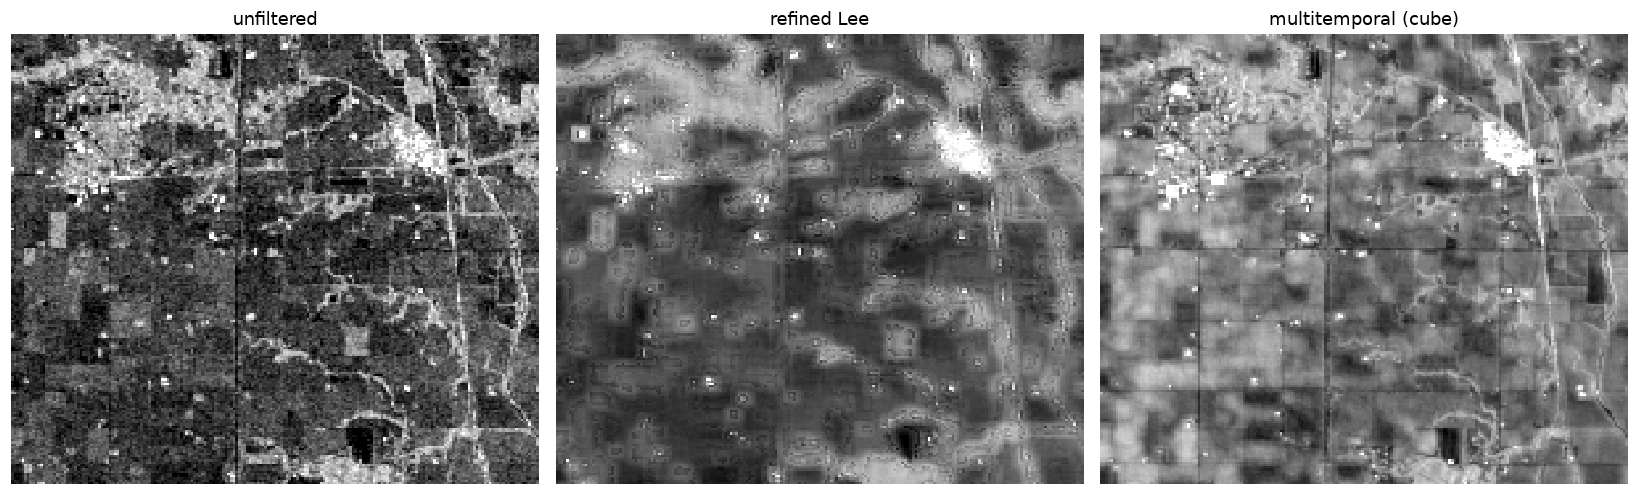

unfiltered: ENL estimate 2.4
multitemporal: ENL estimate 10.3


In [4]:
from geolattice.rsense.sar import speckle  # filters
one = raw.vv.isel(time=0)  # one unfiltered scene (linear)
win = dict(x=slice(int(one.sizes["x"] * 0.4), int(one.sizes["x"] * 0.4) + 200), y=slice(int(one.sizes["y"] * 0.4), int(one.sizes["y"] * 0.4) + 200))  # 10 km window
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))  # raw, Lee, multitemporal
for a, (name, img) in zip(ax, (("unfiltered", one), ("refined Lee", speckle.refined_lee(one)),
                              ("multitemporal (cube)", 10 ** (s1.vv.sel(time=one.time, method="nearest") / 10)))):  # three versions
    (10 * np.log10(img.isel(**win))).plot(ax=a, vmin=-16, vmax=-4, cmap="gray", add_colorbar=False); a.set_title(name); a.axis("off")  # map
plt.tight_layout(); plt.show()  # draw
for name, img in (("unfiltered", one), ("multitemporal", 10 ** (s1.vv.sel(time=one.time, method="nearest") / 10))):  # ENL of a field
    patch = img.isel(x=slice(200, 220), y=slice(200, 220))  # a 1 km block
    print(f"{name}: ENL estimate {speckle.enl_estimate(patch):.1f}")  # equivalent number of looks

The unfiltered 50 m image has an equivalent number of looks of only about 2.4 over a field, so a
single pixel is very noisy. The refined Lee filter smooths within its 7 x 7 window and blurs the field
pattern at this pixel size; the multitemporal filter raises the ENL to about 10 while keeping field
boundaries and roads sharp, because it borrows information from the other 78 dates instead of the
neighbours.

## Masks

{'water': '1.2%', 'urban': '6.6%', 'steep': '0.8%'} | frozen dates: 16 of 79


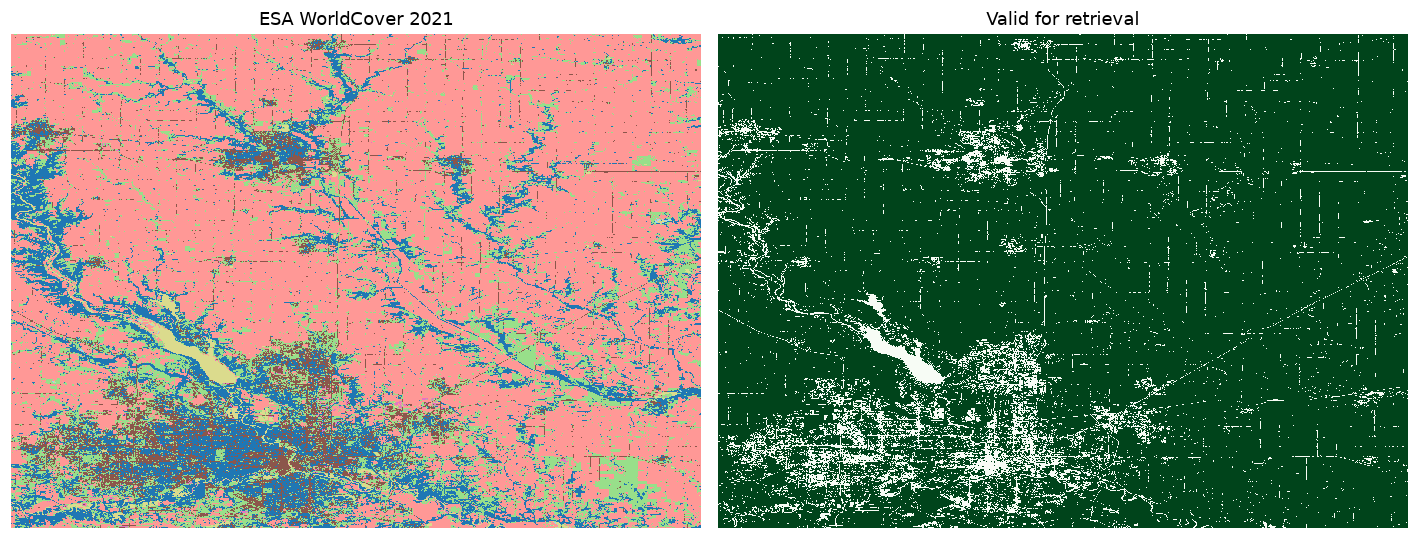

In [5]:
air = sd.uscrn().t_air.resample("1D").mean()  # daily air temperature at the station (C)
masks = sm.sar_masks(s1, dem=stat.dem, landcover=stat.worldcover, max_slope=10.0, temperature=air)  # masks
frac = {k: float(masks[k].mean()) for k in ("water", "urban", "steep")}  # share of the AOI
print({k: f"{v:.1%}" for k, v in frac.items()}, f"| frozen dates: {int(masks.frozen.sum())} of {masks.sizes['time']}")  # summary
fig, ax = plt.subplots(1, 2, figsize=(13, 5))  # land cover and valid mask
stat.worldcover.plot(ax=ax[0], cmap="tab20", add_colorbar=False); ax[0].set_title("ESA WorldCover 2021"); ax[0].axis("off")  # land cover
masks.valid.astype(int).plot(ax=ax[1], cmap="Greens", add_colorbar=False); ax[1].set_title("Valid for retrieval"); ax[1].axis("off")  # valid pixels
plt.tight_layout(); plt.show()  # draw

## VV and VH over corn and soybean

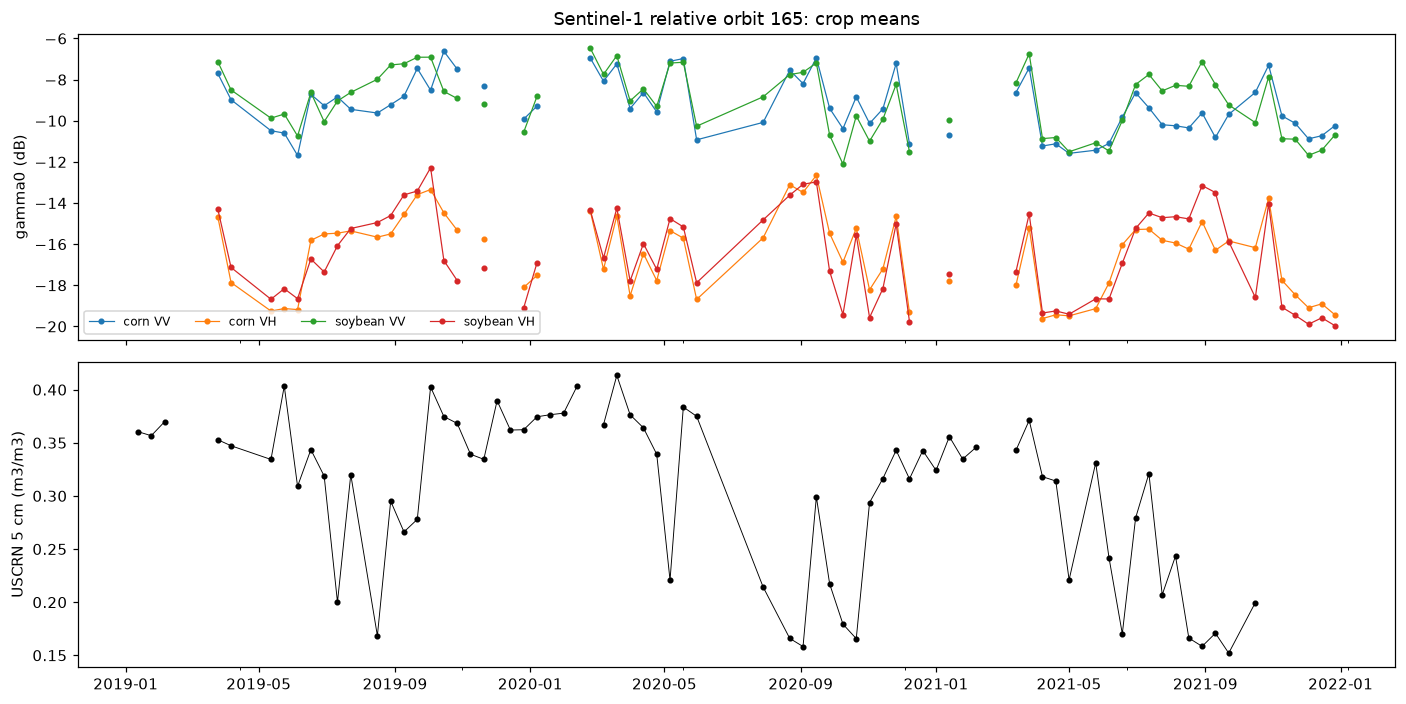

correlation with USCRN 5 cm, April-May and October-November:
{'corn VV': 0.15, 'corn VH': 0.02, 'soybean VV': 0.45, 'soybean VH': 0.26}


In [6]:
crops = {"corn": 1, "soybean": 5}  # CDL codes
valid = masks.valid & ~masks.frozen.broadcast_like(s1.vv)  # unmasked pixels and dates
ts = {}  # mean backscatter per crop and date
for name, code in crops.items():  # each crop
    for yr in (2019, 2020, 2021):  # each year with its own crop map
        sel = (stat[f"cdl_{yr}"] == code) & valid.sel(time=str(yr))  # pixels of that crop in that year
        for pol in ("vv", "vh"):  # both polarizations
            ts.setdefault((name, pol), []).append(s1[pol].sel(time=str(yr)).where(sel).mean(("y", "x")).to_series())  # mean dB
ts = pd.DataFrame({f"{n} {p.upper()}": pd.concat(v) for (n, p), v in ts.items()})  # table
ins = sd.uscrn().sm_5.resample("1D").mean().reindex(ts.index.normalize()).values  # station 5 cm on the same days
fig, ax = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)  # backscatter and in situ
ts.plot(ax=ax[0], marker=".", lw=0.8); ax[0].set_ylabel("gamma0 (dB)"); ax[0].legend(ncol=4, fontsize=8)  # backscatter
ax[1].plot(ts.index, ins, "k.-", lw=0.6); ax[1].set_ylabel("USCRN 5 cm (m3/m3)")  # soil moisture
ax[0].set_title(f"Sentinel-1 relative orbit {s1.attrs['relative_orbit']}: crop means"); plt.tight_layout(); plt.show()  # draw
warm = ts.index.month.isin([4, 5, 10, 11])  # low vegetation months
print("correlation with USCRN 5 cm, April-May and October-November:")  # bare or sparse soil
print(pd.DataFrame(ts[warm]).corrwith(pd.Series(ins[warm], index=ts.index[warm])).round(2).to_dict())  # correlations

VH rises by 4 to 6 dB as corn and soybean grow from May to August and falls at harvest: it is a
vegetation signal. VV carries more of the soil, but even in the low-vegetation months (April, May,
October, November) its correlation with the station's 5 cm series is modest (0.45 over soybean fields
and only 0.15 over corn, whose residue and stalks stay on the field). Part of this is scale: the
station is one point up to 50 km from the fields averaged here, and rain is patchy. In mid-summer the
canopy dominates both polarizations, which is why retrievals over crops need a vegetation correction
(notebook 13) or a change detection that assumes vegetation changes slowly (notebook 12).

The cached cube (`sd.s1_cube()`) is the input of the next notebooks.

## Summary and exercises

- Planetary Computer RTC provides terrain-flattened gamma0 for every Sentinel-1 scene; over central
  Iowa only Sentinel-1A observed in 2019 to 2021, from two ascending relative orbits, every 12 days each.
- Keeping one relative orbit avoids systematic differences of about 0.6 dB between geometries.
- The multitemporal speckle filter raises the ENL from about 2.4 to 10 while keeping field boundaries.
- Water, urban and steep pixels and frozen dates are masked before retrieval.
- VV responds to soil moisture when vegetation is small; VH tracks crop growth.

**Exercises**

1. Build the cube for the other relative orbit with `sd.s1_cube(relative_orbit=...)` and compare the
   crop time series.
2. Use `sm.normalize_incidence` with a slope of -0.15 dB per degree to bring the two orbits to 40
   degrees; does the difference shrink? (Use the scene centre angles from the GRD annotation.)
3. Compute the VH minus VV ratio for corn and soybean. Which crop is easier to separate in July?